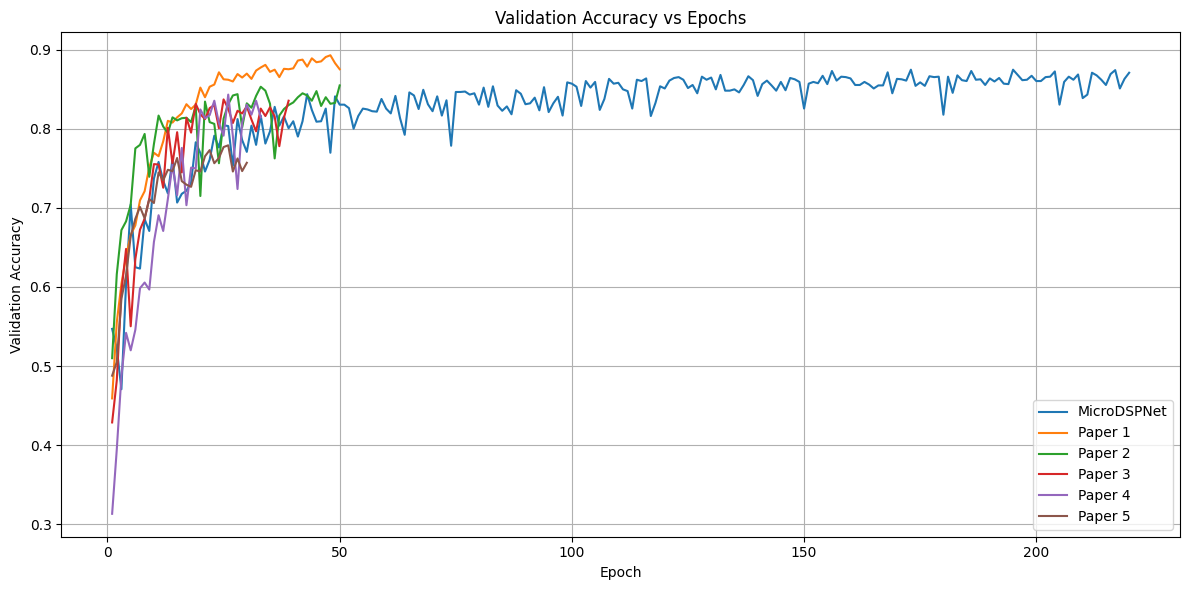

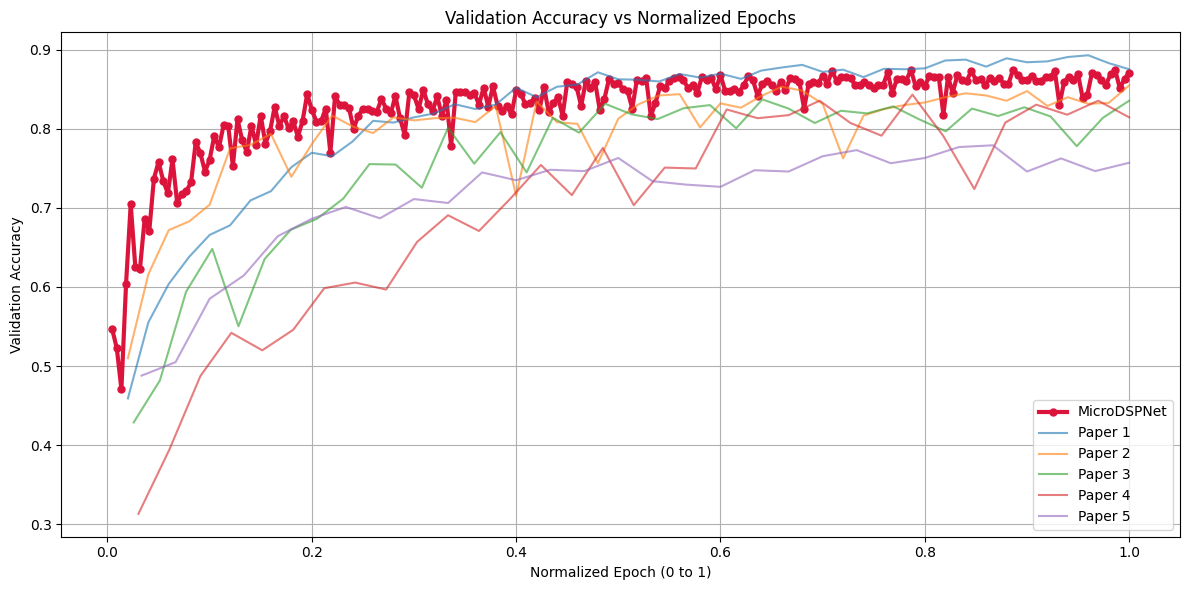

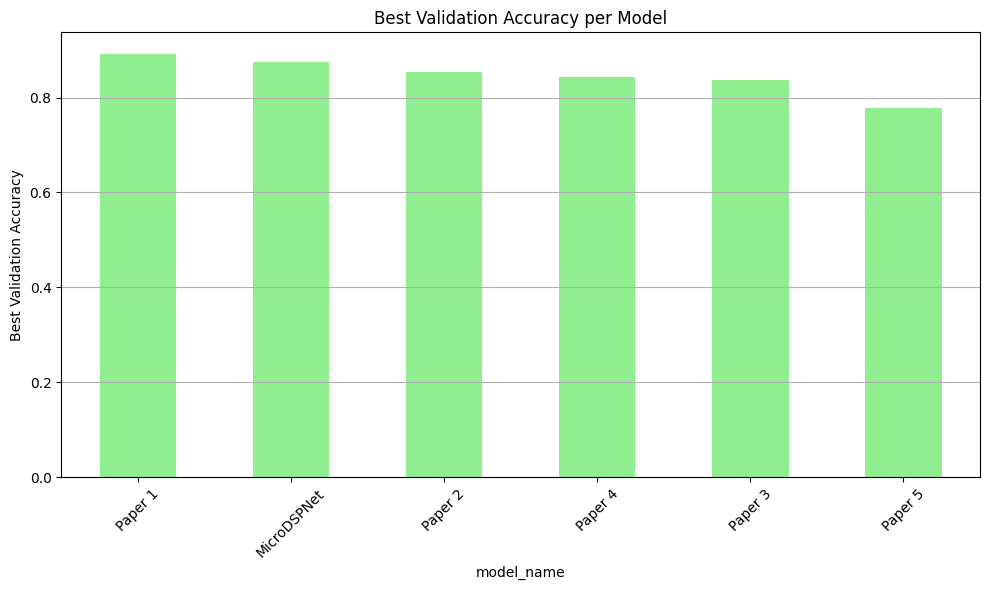

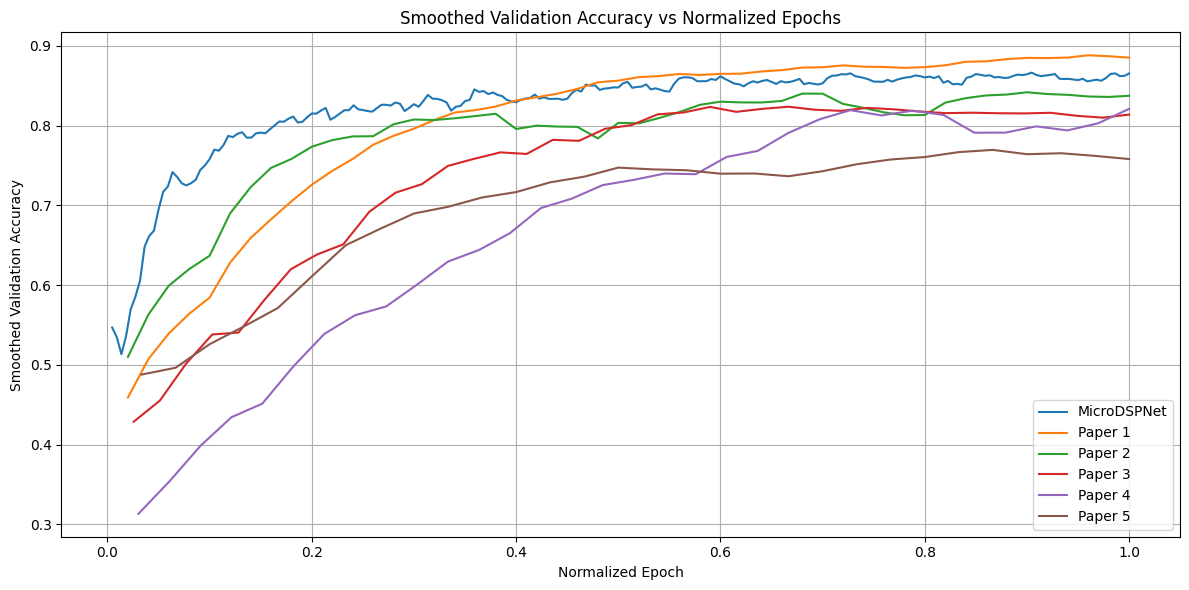

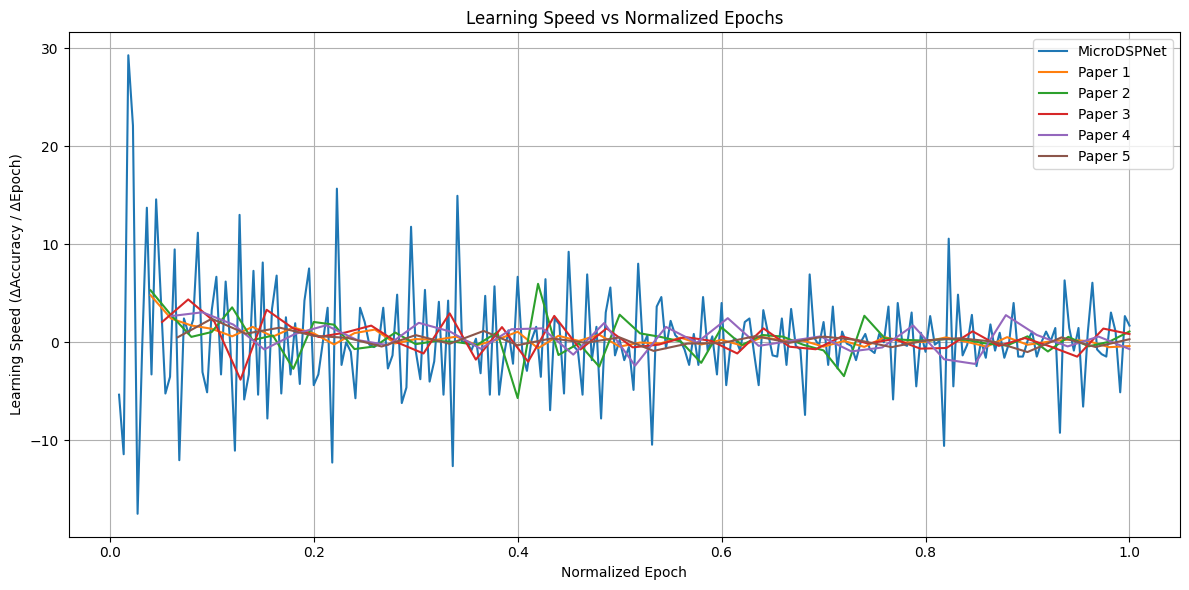

<ipython-input-2-4a3f86b13229>:101: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  final_acc = df_all.groupby('model_name').apply(lambda x: x.loc[x['normalized_epoch'].idxmax(), 'val_accuracy'])


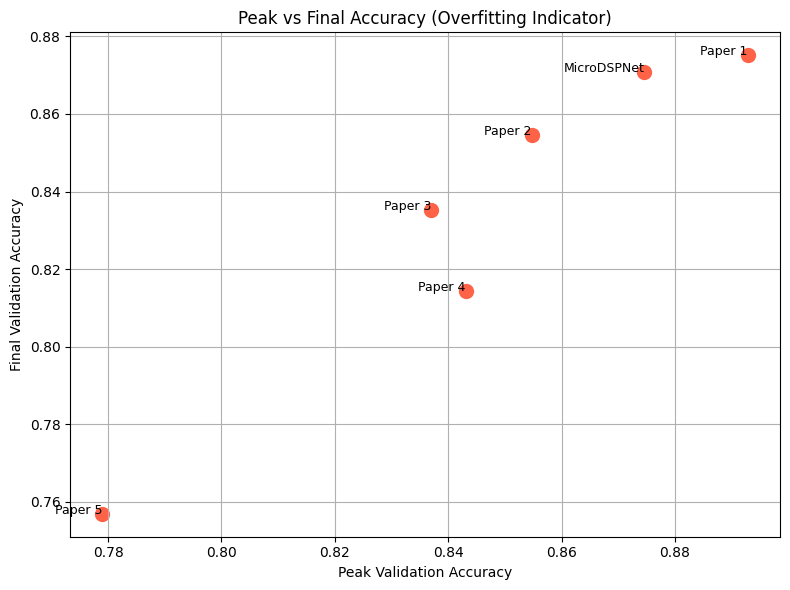

<ipython-input-2-4a3f86b13229>:116: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  peak_epoch = df_all.groupby('model_name').apply(


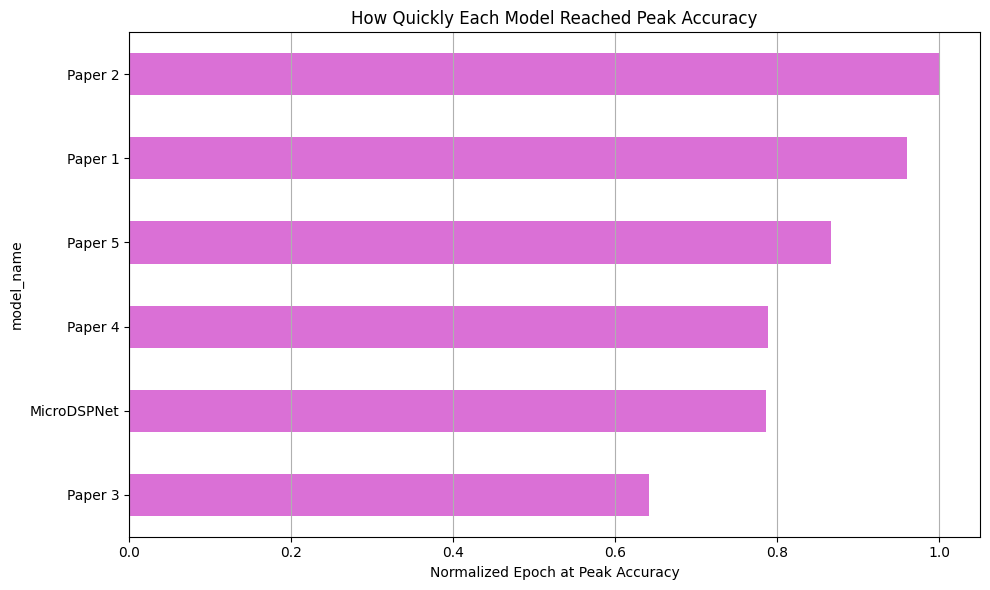

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Replace with your actual file paths and model names
files = [
    '/content/main model.csv',
    '/content/paper1.csv',
    '/content/paper2.csv',
    '/content/paper3.csv',
    '/content/paper4.csv',
    '/content/paper5.csv'
]
model_names = ['MicroDSPNet', 'Paper 1', 'Paper 2', 'Paper 3', 'Paper 4', 'Paper 5']


# Read and label all model data
all_data = []
for file, name in zip(files, model_names):
    df = pd.read_csv(file)
    df['model_name'] = name
    all_data.append(df)

# Merge into one DataFrame
df_all = pd.concat(all_data, ignore_index=True)

# Normalize epochs
df_all['normalized_epoch'] = df_all.groupby('model_name')['epoch'].transform(lambda x: x / x.max())

# ---------- Plot 1: Raw Validation Accuracy vs Epoch ----------
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name]
    plt.plot(model_df['epoch'], model_df['val_accuracy'], label=name)
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy vs Epochs')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------- Plot 2: Normalized Epochs ----------
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name]
    if name == 'MicroDSPNet':
        plt.plot(model_df['normalized_epoch'], model_df['val_accuracy'], label=name,
                 color='crimson', linewidth=3, linestyle='-', marker='o', markersize=5)
    else:
        plt.plot(model_df['normalized_epoch'], model_df['val_accuracy'], label=name, alpha=0.6)
plt.xlabel('Normalized Epoch (0 to 1)')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy vs Normalized Epochs')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ---------- Plot 3: Best Validation Accuracy per Model ----------
best_acc = df_all.groupby('model_name')['val_accuracy'].max().sort_values(ascending=False)
best_acc.plot(kind='bar', figsize=(10, 6), color='lightgreen')
plt.ylabel('Best Validation Accuracy')
plt.title('Best Validation Accuracy per Model')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# ---------- Plot 4: Smoothed Validation Accuracy ----------
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name].copy()
    model_df.sort_values('normalized_epoch', inplace=True)
    model_df['smoothed_acc'] = model_df['val_accuracy'].rolling(window=5, min_periods=1).mean()
    plt.plot(model_df['normalized_epoch'], model_df['smoothed_acc'], label=name)
plt.xlabel('Normalized Epoch')
plt.ylabel('Smoothed Validation Accuracy')
plt.title('Smoothed Validation Accuracy vs Normalized Epochs')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------- Plot 5: Learning Speed (Accuracy Derivative) ----------
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name].copy()
    model_df.sort_values('normalized_epoch', inplace=True)
    model_df['learning_speed'] = model_df['val_accuracy'].diff() / model_df['normalized_epoch'].diff()
    plt.plot(model_df['normalized_epoch'], model_df['learning_speed'], label=name)
plt.xlabel('Normalized Epoch')
plt.ylabel('Learning Speed (ΔAccuracy / ΔEpoch)')
plt.title('Learning Speed vs Normalized Epochs')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------- Plot 6: Peak vs Final Accuracy ----------
final_acc = df_all.groupby('model_name').apply(lambda x: x.loc[x['normalized_epoch'].idxmax(), 'val_accuracy'])
peak_acc = df_all.groupby('model_name')['val_accuracy'].max()

plt.figure(figsize=(8, 6))
plt.scatter(peak_acc, final_acc, s=100, color='tomato')
for name in df_all['model_name'].unique():
    plt.text(peak_acc[name], final_acc[name], name, fontsize=9, ha='right')
plt.xlabel('Peak Validation Accuracy')
plt.ylabel('Final Validation Accuracy')
plt.title('Peak vs Final Accuracy (Overfitting Indicator)')
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------- Plot 7: Epochs to Peak Accuracy ----------
peak_epoch = df_all.groupby('model_name').apply(
    lambda x: x.loc[x['val_accuracy'].idxmax(), 'normalized_epoch'])

peak_epoch.sort_values().plot(kind='barh', figsize=(10, 6), color='orchid')
plt.xlabel('Normalized Epoch at Peak Accuracy')
plt.title('How Quickly Each Model Reached Peak Accuracy')
plt.grid(axis='x')
plt.tight_layout()
plt.show()


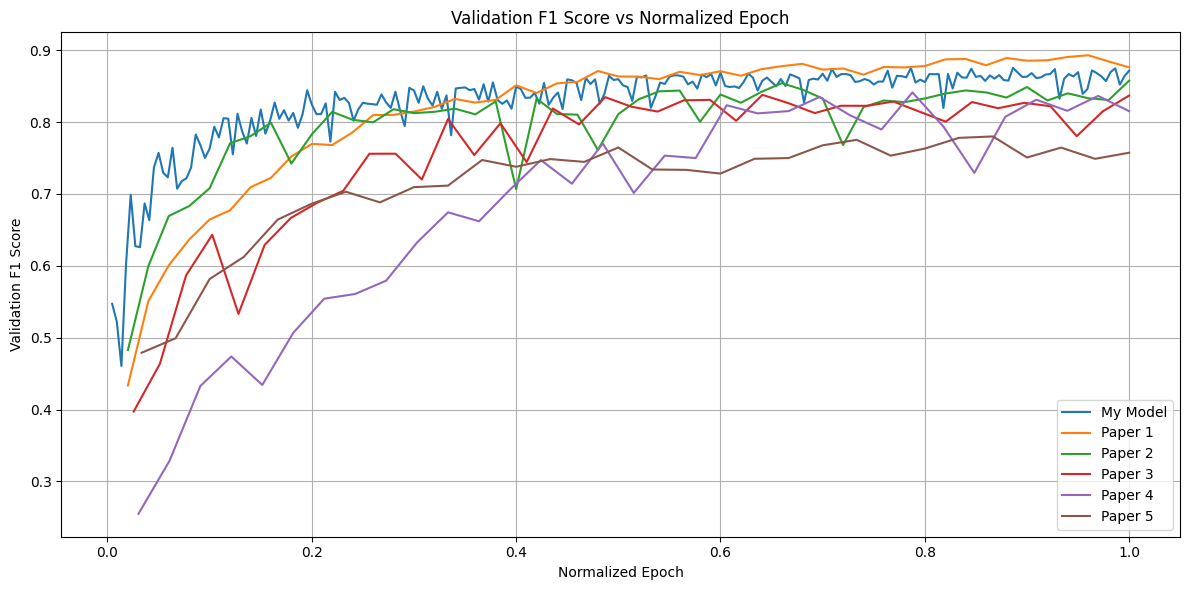

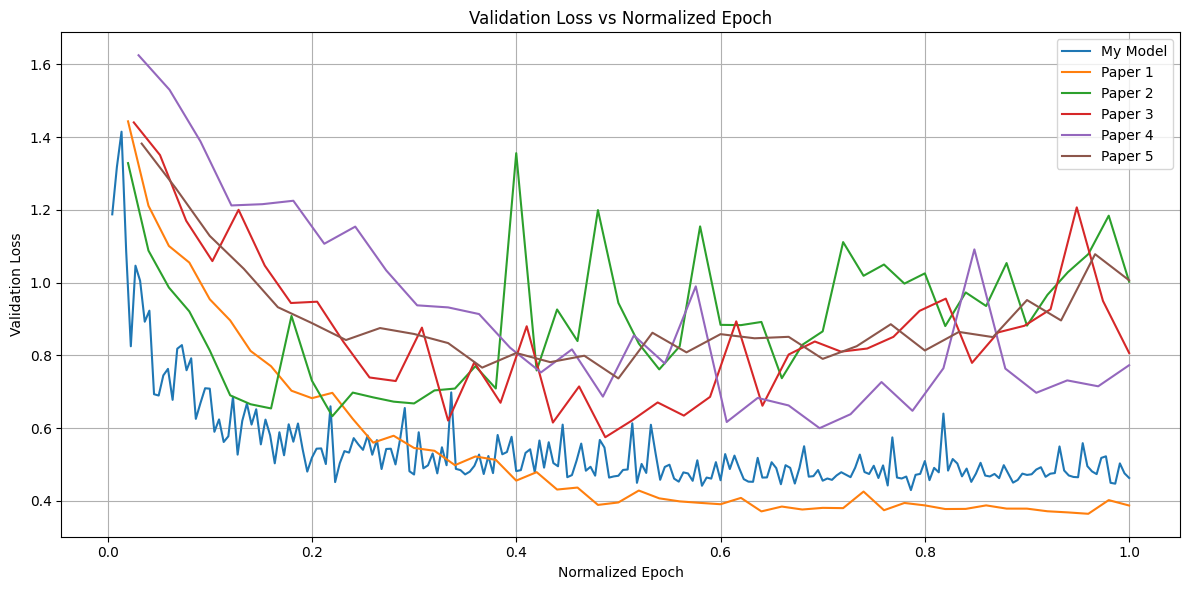

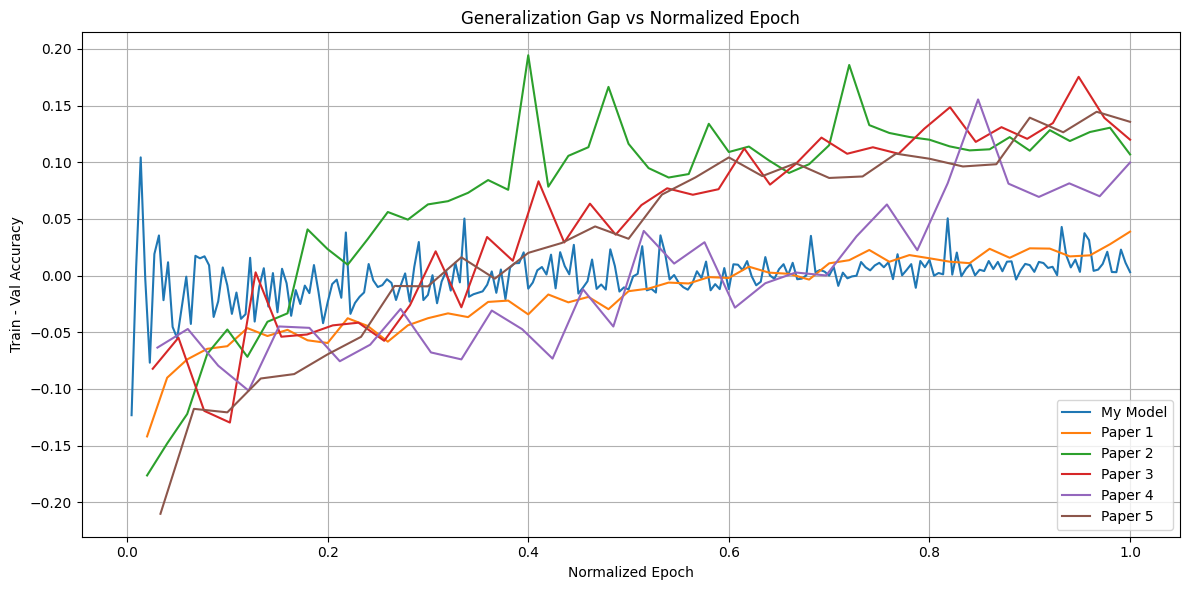

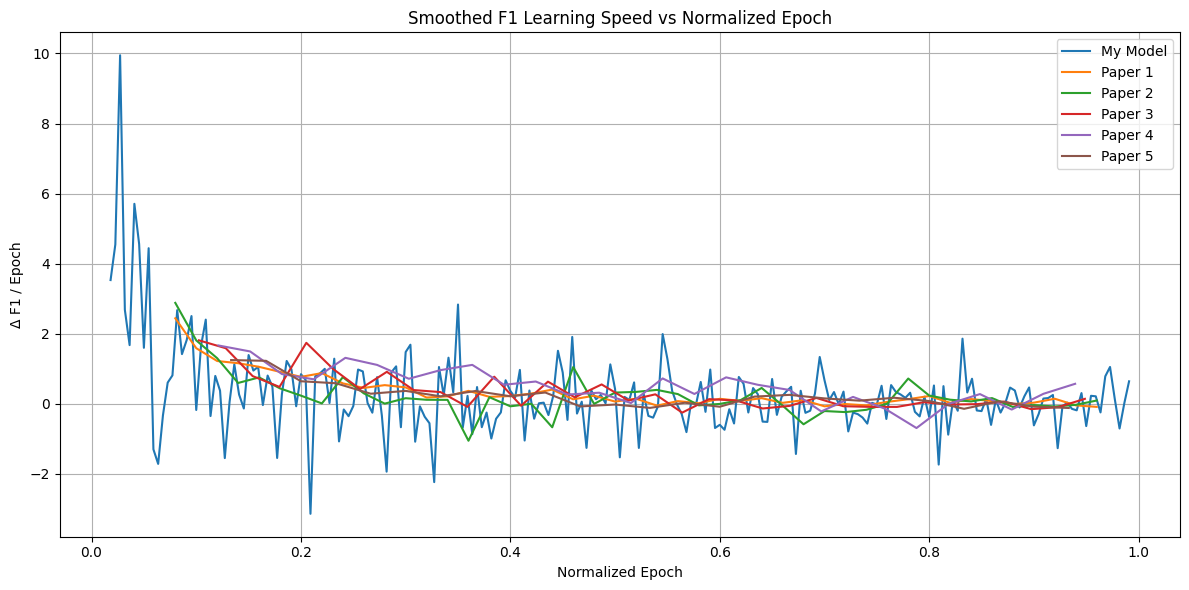

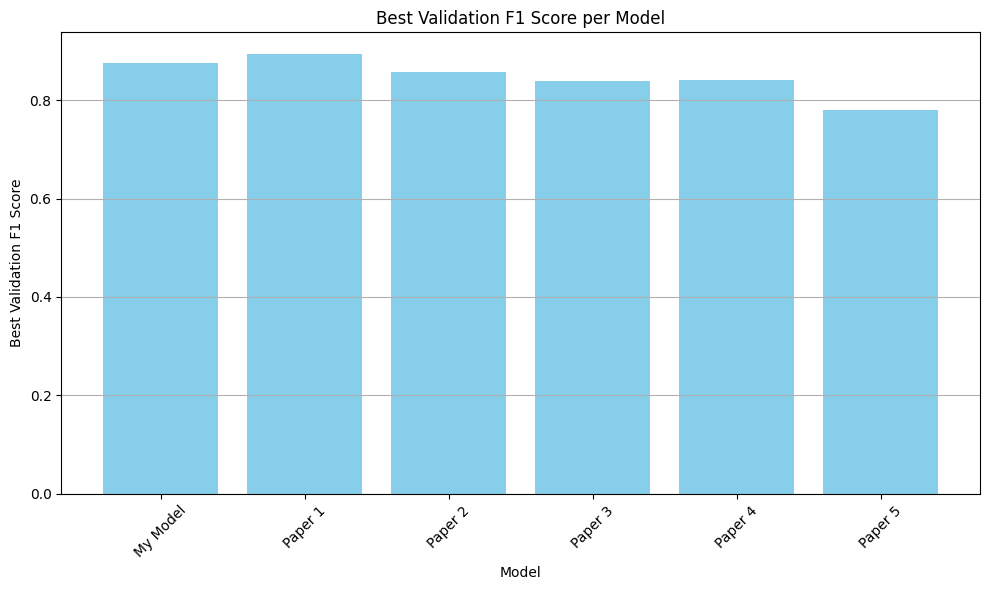

🏆 Best F1 Scores and Corresponding Epochs:
    model_name  epoch  val_f1_score
267    Paper 1     48      0.892920
194   My Model    195      0.875333
319    Paper 2     50      0.857603
384    Paper 4     26      0.841251
344    Paper 3     25      0.837886
417    Paper 5     26      0.780006


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# File paths and model names
files = [
    '/content/main model.csv', '/content/paper1.csv', '/content/paper2.csv',
    '/content/paper3.csv', '/content/paper4.csv', '/content/paper5.csv'
]
model_names = ['My Model', 'Paper 1', 'Paper 2', 'Paper 3', 'Paper 4', 'Paper 5']

# Load and tag each DataFrame
all_data = []
for file, name in zip(files, model_names):
    df = pd.read_csv(file)
    df['model_name'] = name
    all_data.append(df)

# Combine all into a single DataFrame
df_all = pd.concat(all_data, ignore_index=True)

# Normalize epochs
df_all['normalized_epoch'] = df_all.groupby('model_name')['epoch'].transform(lambda x: x / x.max())

# ---------------------- Plot 1: Validation F1 Score vs Normalized Epoch ----------------------
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name]
    plt.plot(model_df['normalized_epoch'], model_df['val_f1_score'], label=name)
plt.xlabel('Normalized Epoch')
plt.ylabel('Validation F1 Score')
plt.title('Validation F1 Score vs Normalized Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------------- Plot 2: Validation Loss vs Normalized Epoch ----------------------
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name]
    plt.plot(model_df['normalized_epoch'], model_df['val_loss'], label=name)
plt.xlabel('Normalized Epoch')
plt.ylabel('Validation Loss')
plt.title('Validation Loss vs Normalized Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------------- Plot 3: Generalization Gap vs Normalized Epoch ----------------------
df_all['generalization_gap'] = df_all['accuracy'] - df_all['val_accuracy']
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name]
    plt.plot(model_df['normalized_epoch'], model_df['generalization_gap'], label=name)
plt.xlabel('Normalized Epoch')
plt.ylabel('Train - Val Accuracy')
plt.title('Generalization Gap vs Normalized Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------------- Plot 4: Smoothed F1 Learning Speed vs Normalized Epoch ----------------------
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name].copy()
    model_df = model_df.sort_values('normalized_epoch')
    model_df['f1_speed'] = model_df['val_f1_score'].diff() / model_df['normalized_epoch'].diff()
    model_df['f1_speed_smooth'] = model_df['f1_speed'].rolling(window=5, center=True).mean()
    plt.plot(model_df['normalized_epoch'], model_df['f1_speed_smooth'], label=name)
plt.xlabel('Normalized Epoch')
plt.ylabel('Δ F1 / Epoch')
plt.title('Smoothed F1 Learning Speed vs Normalized Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------------- Plot 5: Epoch of Best F1 Score ----------------------
peak_f1 = df_all.loc[df_all.groupby('model_name')['val_f1_score'].idxmax()]
plt.figure(figsize=(10, 6))
plt.bar(peak_f1['model_name'], peak_f1['val_f1_score'], color='skyblue')
plt.xlabel('Model')
plt.ylabel('Best Validation F1 Score')
plt.title('Best Validation F1 Score per Model')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Print table of best F1 scores and their epoch
print("🏆 Best F1 Scores and Corresponding Epochs:")
print(peak_f1[['model_name', 'epoch', 'val_f1_score']].sort_values(by='val_f1_score', ascending=False))


In [ ]:
pip install tensorflow keras-flops


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model
from tensorflow.keras import backend as K
import numpy as np
import time

# Constants
IMG_DIM = 51
NUM_CLASSES = 6

# ========== Paper1 Model ==========
def paper1_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (3, 3), strides=(1, 1), padding="same", activation='relu', input_shape=(IMG_DIM, IMG_DIM, 3)),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(256, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    return model

# ========== Paper2 Model ==========
def dilated_deformable_conv(x, filters, kernel_size, dilation_rate=1):
    conv = layers.Conv2D(filters, kernel_size, dilation_rate=dilation_rate, padding='same', activation=None)(x)
    bn = layers.BatchNormalization()(conv)
    activation = layers.Activation('swish')(bn)
    return activation

def depthwise_conv(x, filters, kernel_size, strides=1):
    depthwise = layers.DepthwiseConv2D(kernel_size, strides=strides, padding='same')(x)
    bn = layers.BatchNormalization()(depthwise)
    activation = layers.Activation('swish')(bn)
    conv = layers.Conv2D(filters, (1, 1), padding='same', activation='swish')(activation)
    return conv

def paper2_model():
    input_layer = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))
    x = layers.Conv2D(32, (3, 3), padding='same', activation='swish')(input_layer)
    x = dilated_deformable_conv(x, 64, (3, 3), dilation_rate=1)
    x = dilated_deformable_conv(x, 128, (3, 3), dilation_rate=2)
    x = dilated_deformable_conv(x, 256, (3, 3), dilation_rate=4)

    x = layers.MaxPooling2D(pool_size=(5, 5), strides=1, padding='same')(x)
    x = layers.MaxPooling2D(pool_size=(9, 9), strides=1, padding='same')(x)
    x = layers.MaxPooling2D(pool_size=(13, 13), strides=1, padding='same')(x)

    x = depthwise_conv(x, 128, (3, 3))
    x = depthwise_conv(x, 64, (3, 3))
    x = depthwise_conv(x, 32, (3, 3))

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.6)(x)
    output = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inputs=input_layer, outputs=output)

# ========== Paper3 Model ==========
class RepVGGBlock(tf.keras.layers.Layer):
    def __init__(self, filters, kernel_size=3, stride=1, use_identity=True):
        super().__init__()
        self.conv3x3 = layers.Conv2D(filters, kernel_size, strides=stride, padding='same', use_bias=False)
        self.bn3x3 = layers.BatchNormalization()
        self.conv1x1 = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)
        self.bn1x1 = layers.BatchNormalization()

        self.identity = layers.BatchNormalization() if use_identity else None
        self.relu = layers.ReLU()

    def call(self, inputs, training=False):
        x1 = self.relu(self.bn3x3(self.conv3x3(inputs), training=training))
        x2 = self.relu(self.bn1x1(self.conv1x1(inputs), training=training))
        x3 = self.identity(inputs) if self.identity else 0
        return self.relu(x1 + x2 + x3)

class MSCA_Module(tf.keras.layers.Layer):
    def __init__(self, filters):
        super().__init__()
        self.conv1 = layers.Conv2D(filters // 2, 1, activation='relu', padding='same')
        self.conv3 = layers.Conv2D(filters // 2, 3, activation='relu', padding='same')
        self.conv5 = layers.Conv2D(filters, 5, activation='relu', padding='same')
        self.bn = layers.BatchNormalization()

    def call(self, inputs, training=False):
        x1 = self.conv1(inputs)
        x2 = self.conv3(inputs)
        x3 = self.conv5(inputs)
        x = tf.concat([x1, x2, x3], axis=-1)
        return self.bn(x, training=training)

def paper3_model():
    inputs = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))
    x = RepVGGBlock(64, stride=2)(inputs)
    x = RepVGGBlock(128, stride=2)(x)
    x = RepVGGBlock(256, stride=2)(x)
    x = MSCA_Module(256)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    output = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(inputs, output)

# ========== Paper4 Model ==========
class GSConv(tf.keras.layers.Layer):
    def __init__(self, out_channels):
        super().__init__()
        self.conv1 = layers.Conv2D(out_channels // 2, 1, padding='same', activation='relu')
        self.conv2 = layers.Conv2D(out_channels // 2, 3, padding='same', activation='relu')

    def call(self, x):
        x1 = self.conv1(x)
        x2 = self.conv2(x)
        return tf.concat([x1, x2], axis=-1)

class GRSCPSELAN(tf.keras.layers.Layer):
    def __init__(self, filters):
        super().__init__()
        self.conv1 = layers.Conv2D(filters, 3, padding='same', activation='relu')
        self.conv2 = layers.Conv2D(filters, 3, padding='same', activation='relu')
        self.shortcut = layers.Conv2D(filters, 1, padding='same')
        self.bn = layers.BatchNormalization()
        self.relu = layers.ReLU()

    def call(self, x, training=False):
        residual = self.shortcut(x)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.bn(x + residual, training=training)
        return self.relu(x)

def paper4_model():
    inputs = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))
    x = layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
    x = GRSCPSELAN(64)(x)
    x = layers.MaxPooling2D()(x)
    x = GRSCPSELAN(128)(x)
    x = layers.MaxPooling2D()(x)
    x = GRSCPSELAN(256)(x)
    x = GSConv(256)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(inputs, outputs)

# ========== Paper5 Model ==========
def multi_block(x, filters, stride=1):
    d3 = layers.DepthwiseConv2D(3, strides=stride, padding='same', use_bias=False)(x)
    d5 = layers.DepthwiseConv2D(5, strides=stride, padding='same', use_bias=False)(x)
    d7 = layers.DepthwiseConv2D(7, strides=stride, padding='same', use_bias=False)(x)

    d3 = layers.ReLU()(layers.BatchNormalization()(d3))
    d5 = layers.ReLU()(layers.BatchNormalization()(d5))
    d7 = layers.ReLU()(layers.BatchNormalization()(d7))

    concat = layers.Concatenate()([d3, d5, d7])
    pw = layers.Conv2D(filters, 1, padding='same', use_bias=False)(concat)
    pw = layers.BatchNormalization()(pw)
    return layers.ReLU()(pw)

def paper5_model():
    input_layer = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))
    x = layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False)(input_layer)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = multi_block(x, 64, stride=2)
    x = multi_block(x, 96, stride=2)
    x = multi_block(x, 128, stride=2)
    x = multi_block(x, 128)
    x = multi_block(x, 192)

    x = layers.Conv2D(192, 1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.6)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.7)(x)
    output = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(input_layer, output)

# ========== Proposed Model ==========
def proposed_model():
    model = tf.keras.Sequential([
        layers.Conv2D(32, kernel_size=(3, 3), strides=(2, 2), padding="same", activation='relu', input_shape=(IMG_DIM, IMG_DIM, 3)),
        layers.BatchNormalization(),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(48, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(96, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
        layers.Dropout(0.2),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
        layers.Dropout(0.2),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        layers.Dense(64, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.2),

        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    return model

# ========== Parameter Calculation ==========
def calculate_model_metrics(model_fn, model_name):
    # Create model
    model = model_fn()

    # Calculate parameters
    trainable_params = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable_params = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable_params + non_trainable_params

    # Estimate computational complexity by running a sample through the model
    # and measuring execution time
    dummy_input = np.zeros((1, IMG_DIM, IMG_DIM, 3), dtype=np.float32)

    # Warmup run
    model(dummy_input)

    # Timed runs
    num_runs = 10
    start_time = time.time()
    for _ in range(num_runs):
        model(dummy_input)
    end_time = time.time()

    avg_execution_time = (end_time - start_time) / num_runs

    print(f"\n{model_name} Summary:")
    print(f"- Trainable parameters: {trainable_params:,}")
    print(f"- Non-trainable parameters: {non_trainable_params:,}")
    print(f"- Total parameters: {total_params:,}")
    print(f"- Average execution time: {avg_execution_time * 1000:.2f} ms")

    # Get model summary as string
    model_summary = []
    model.summary(print_fn=lambda x: model_summary.append(x))
    model_summary = '\n'.join(model_summary)

    return {
        "model_name": model_name,
        "trainable_params": trainable_params,
        "non_trainable_params": non_trainable_params,
        "total_params": total_params,
        "execution_time": avg_execution_time,
        "summary": model_summary
    }

# ========== Utility to Compare Models ==========
def compare_models(metrics_list):
    # Sort models by execution time (proxy for computational efficiency)
    sorted_by_time = sorted(metrics_list, key=lambda x: x["execution_time"])

    print("\n===== Models Ranked by Computational Efficiency (Lower execution time is better) =====")
    for i, metrics in enumerate(sorted_by_time):
        print(f"{i+1}. {metrics['model_name']}: {metrics['execution_time'] * 1000:.2f} ms, {metrics['total_params']:,} parameters")

    # Sort models by parameter count
    sorted_by_params = sorted(metrics_list, key=lambda x: x["total_params"])

    print("\n===== Models Ranked by Parameter Efficiency (Fewer parameters is better) =====")
    for i, metrics in enumerate(sorted_by_params):
        print(f"{i+1}. {metrics['model_name']}: {metrics['total_params']:,} parameters, {metrics['execution_time'] * 1000:.2f} ms")

    # Find the most efficient model (best balance of parameters and execution time)
    # Using a simple scoring system: rank_by_time + rank_by_params
    for i, metrics in enumerate(sorted_by_time):
        metrics["time_rank"] = i + 1

    for i, metrics in enumerate(sorted_by_params):
        metrics["param_rank"] = i + 1

    for metrics in metrics_list:
        metrics["efficiency_score"] = metrics["time_rank"] + metrics["param_rank"]

    sorted_by_efficiency = sorted(metrics_list, key=lambda x: x["efficiency_score"])

    print("\n===== Models Ranked by Overall Efficiency (Lower score is better) =====")
    for i, metrics in enumerate(sorted_by_efficiency):
        print(f"{i+1}. {metrics['model_name']}: Score {metrics['efficiency_score']}, "
              f"Time: {metrics['execution_time'] * 1000:.2f} ms, "
              f"Params: {metrics['total_params']:,}")

# ========== Function to Save Detailed Report ==========
def save_detailed_report(metrics_list, filename="model_comparison_report.txt"):
    with open(filename, "w") as f:
        f.write("=== CNN MODEL COMPARISON REPORT ===\n\n")

        # Execution time comparison
        f.write("COMPUTATIONAL EFFICIENCY RANKING:\n")
        sorted_by_time = sorted(metrics_list, key=lambda x: x["execution_time"])
        for i, metrics in enumerate(sorted_by_time):
            f.write(f"{i+1}. {metrics['model_name']}: {metrics['execution_time'] * 1000:.2f} ms, {metrics['total_params']:,} parameters\n")

        f.write("\nPARAMETER EFFICIENCY RANKING:\n")
        sorted_by_params = sorted(metrics_list, key=lambda x: x["total_params"])
        for i, metrics in enumerate(sorted_by_params):
            f.write(f"{i+1}. {metrics['model_name']}: {metrics['total_params']:,} parameters, {metrics['execution_time'] * 1000:.2f} ms\n")

        # Overall efficiency
        sorted_by_efficiency = sorted(metrics_list, key=lambda x: x["efficiency_score"])
        f.write("\nOVERALL EFFICIENCY RANKING:\n")
        for i, metrics in enumerate(sorted_by_efficiency):
            f.write(f"{i+1}. {metrics['model_name']}: Score {metrics['efficiency_score']}, "
                  f"Time Rank: {metrics['time_rank']}, "
                  f"Param Rank: {metrics['param_rank']}\n")

        # Detailed summaries
        f.write("\n=== DETAILED MODEL SUMMARIES ===\n")
        for metrics in metrics_list:
            f.write(f"\n--- {metrics['model_name']} ---\n")
            f.write(f"Execution time: {metrics['execution_time'] * 1000:.2f} ms\n")
            f.write(f"Total parameters: {metrics['total_params']:,}\n")
            f.write(f"Trainable parameters: {metrics['trainable_params']:,}\n")
            f.write(f"Non-trainable parameters: {metrics['non_trainable_params']:,}\n\n")
            f.write(metrics["summary"])
            f.write("\n\n")

    print(f"\nDetailed report saved to {filename}")

# ========== Main Execution ==========
def main():
    # List of all models and their names
    models = [
        (paper1_model, "Paper 1 Model"),
        (paper2_model, "Paper 2 Model"),
        (paper3_model, "Paper 3 Model"),
        (paper4_model, "Paper 4 Model"),
        (paper5_model, "Paper 5 Model"),
        (proposed_model, "Proposed Model")
    ]

    # Calculate metrics for all models
    all_metrics = []
    for model_fn, model_name in models:
        try:
            print(f"\nProcessing {model_name}...")
            metrics = calculate_model_metrics(model_fn, model_name)
            all_metrics.append(metrics)
        except Exception as e:
            print(f"Error calculating metrics for {model_name}: {e}")

    # Compare all models
    compare_models(all_metrics)

    # Save detailed report
    save_detailed_report(all_metrics)

    # Output a detailed model summary of the proposed model
    print("\n===== Detailed Summary of Proposed Model =====")
    proposed = proposed_model()
    proposed.summary()

if __name__ == "__main__":
    main()


Processing Paper 1 Model...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Paper 1 Model Summary:
- Trainable parameters: 588,998
- Non-trainable parameters: 0.0
- Total parameters: 588,998.0
- Average execution time: 104.68 ms



Processing Paper 2 Model...

Paper 2 Model Summary:
- Trainable parameters: 442,310
- Non-trainable parameters: 1,792
- Total parameters: 444,102
- Average execution time: 210.92 ms



Processing Paper 3 Model...
Error calculating metrics for Paper 3 Model: Exception encountered when calling RepVGGBlock.call().

Could not automatically infer the output shape / dtype of 'rep_vgg_block' (of type RepVGGBlock). Either the `RepVGGBlock.call()` method is incorrect, or you need to implement the `RepVGGBlock.compute_output_spec() / compute_output_shape()` method. Error encountered:

Dimensions must be equal, but are 26 and 51 for '{{node add_1}} = AddV2[T=DT_FLOAT](add, batch_normalization_8_1/batchnorm/add_1)' with input shapes: [?,26,26,64], [?,51,51,3].

Arguments received by RepVGGBlock.call():
  • args=('<KerasTensor shape=(None, 51, 51, 3), dtype=float32, sparse=False, name=keras_tensor_52>',)
  • kwargs={'training': 'False'}

Processing Paper 4 Model...


...

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_38 (Conv2D)              │ (None, 26, 26, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_22             │ (None, 26, 26, 32)     │           320 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 26, 26, 48)     │         1,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_45          │ (None, 26, 26, 48)     │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 13, 13, 48)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_23             │ (None, 13, 13, 48)     │           480 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_46          │ (None, 13, 13, 48)     │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 13, 13, 96)     │         4,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_47          │ (None, 13, 13, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 6, 6, 96)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 6, 6, 96)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_24             │ (None, 6, 6, 96)       │           960 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_48          │ (None, 6, 6, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 6, 6, 128)      │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 6, 6, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 3, 3, 128)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 52,630 (205.59 KB)

 Trainable params: 51,158 (199.84 KB)

 Non-trainable params: 1,472 (5.75 KB)

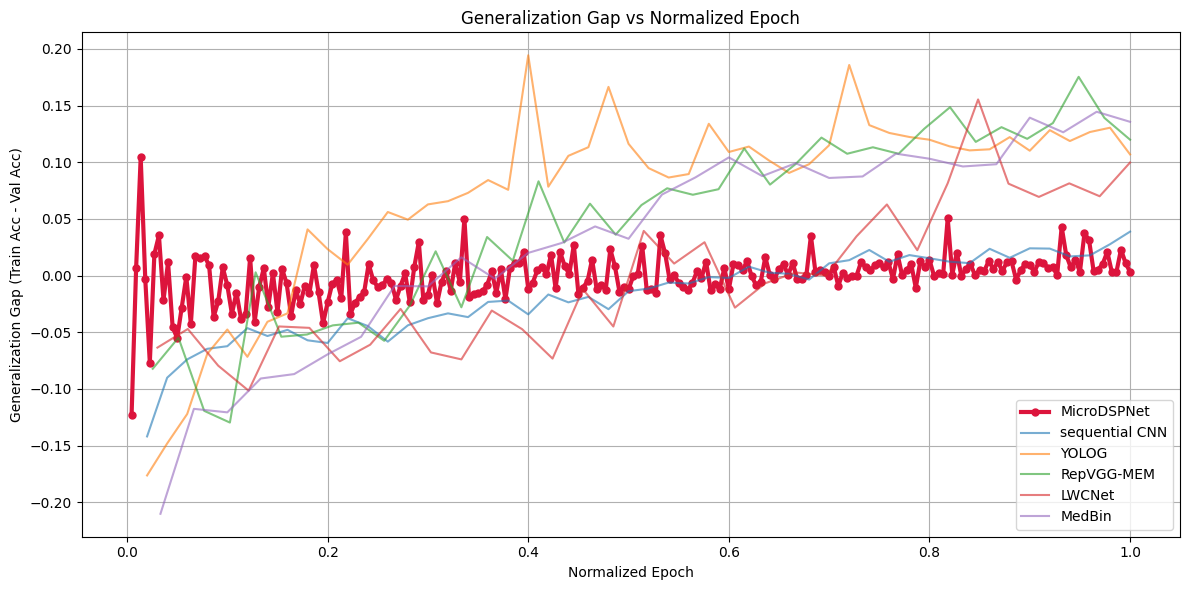

✅ Plot saved to /content/generalization_gap.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# File paths and model names
files = [
    '/content/main model.csv', '/content/paper1.csv', '/content/paper2.csv',
    '/content/paper3.csv', '/content/paper4.csv', '/content/paper5.csv'
]
model_names = ['MicroDSPNet', 'sequential CNN', 'YOLOG', 'RepVGG-MEM', 'LWCNet', 'MedBin']

# Load and tag each DataFrame
all_data = []
for file, name in zip(files, model_names):
    df = pd.read_csv(file)
    df['model_name'] = name
    all_data.append(df)

# Combine all into a single DataFrame
df_all = pd.concat(all_data, ignore_index=True)

# Normalize epochs
df_all['normalized_epoch'] = df_all.groupby('model_name')['epoch'].transform(lambda x: x / x.max())

# Calculate Generalization Gap
df_all['generalization_gap'] = df_all['accuracy'] - df_all['val_accuracy']

# Create and save the plot
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name]
    if name == 'MicroDSPNet':
        plt.plot(model_df['normalized_epoch'], model_df['generalization_gap'],
                 label=name, color='crimson', linewidth=3, marker='o', markersize=5)
    else:
        plt.plot(model_df['normalized_epoch'], model_df['generalization_gap'],
                 label=name, alpha=0.6)
plt.xlabel('Normalized Epoch')
plt.ylabel('Generalization Gap (Train Acc - Val Acc)')
plt.title('Generalization Gap vs Normalized Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save the plot
output_path = '/content/generalization_gap.png'
plt.savefig(output_path, dpi=300)
plt.show()

print(f"✅ Plot saved to {output_path}")


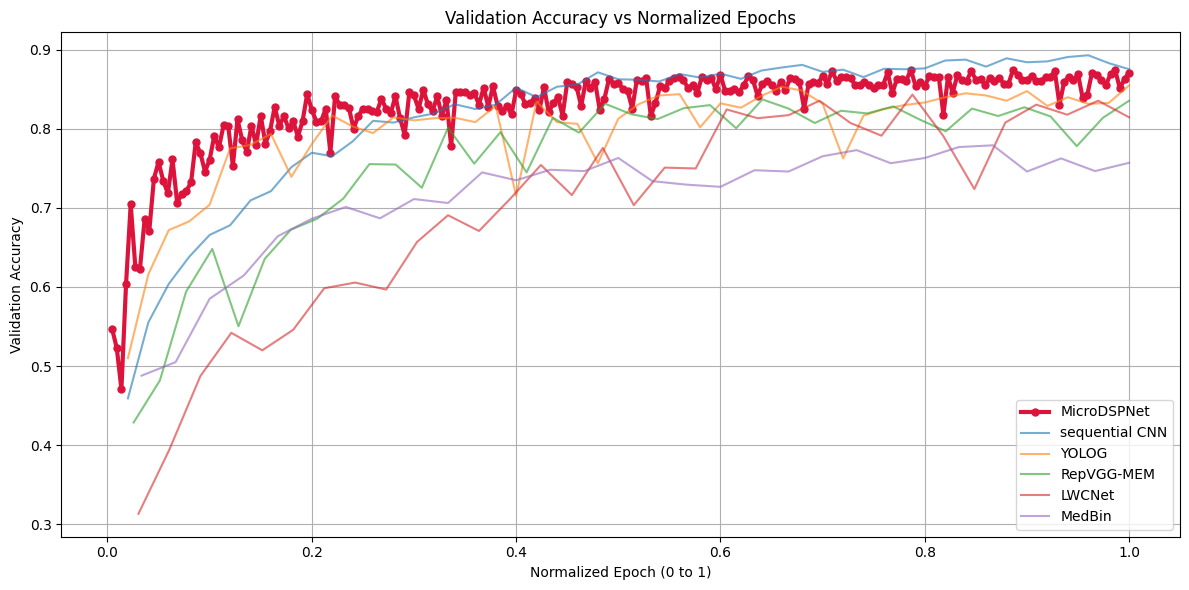

Plot saved to /content/val_accuracy_normalized.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Define file paths and model names
files = [
    '/content/main model.csv',
    '/content/paper1.csv',
    '/content/paper2.csv',
    '/content/paper3.csv',
    '/content/paper4.csv',
    '/content/paper5.csv'
]
model_names = ['MicroDSPNet', 'sequential CNN', 'YOLOG', 'RepVGG-MEM', 'LWCNet', 'MedBin']

# Read and label all model data
all_data = []
for file, name in zip(files, model_names):
    df = pd.read_csv(file)
    df['model_name'] = name
    all_data.append(df)

# Merge into one DataFrame
df_all = pd.concat(all_data, ignore_index=True)

# Normalize epochs
df_all['normalized_epoch'] = df_all.groupby('model_name')['epoch'].transform(lambda x: x / x.max())

# Create and save the plot
plt.figure(figsize=(12, 6))
for name in df_all['model_name'].unique():
    model_df = df_all[df_all['model_name'] == name]
    if name == 'MicroDSPNet':
        plt.plot(model_df['normalized_epoch'], model_df['val_accuracy'], label=name,
                 color='crimson', linewidth=3, linestyle='-', marker='o', markersize=5)
    else:
        plt.plot(model_df['normalized_epoch'], model_df['val_accuracy'], label=name, alpha=0.6)
plt.xlabel('Normalized Epoch (0 to 1)')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy vs Normalized Epochs')
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save the plot
output_path = '/content/val_accuracy_normalized.png'
plt.savefig(output_path, dpi=300)
plt.show()

print(f"Plot saved to {output_path}")


<ipython-input-6-5b0e53f80419>:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab10', len(model_data))


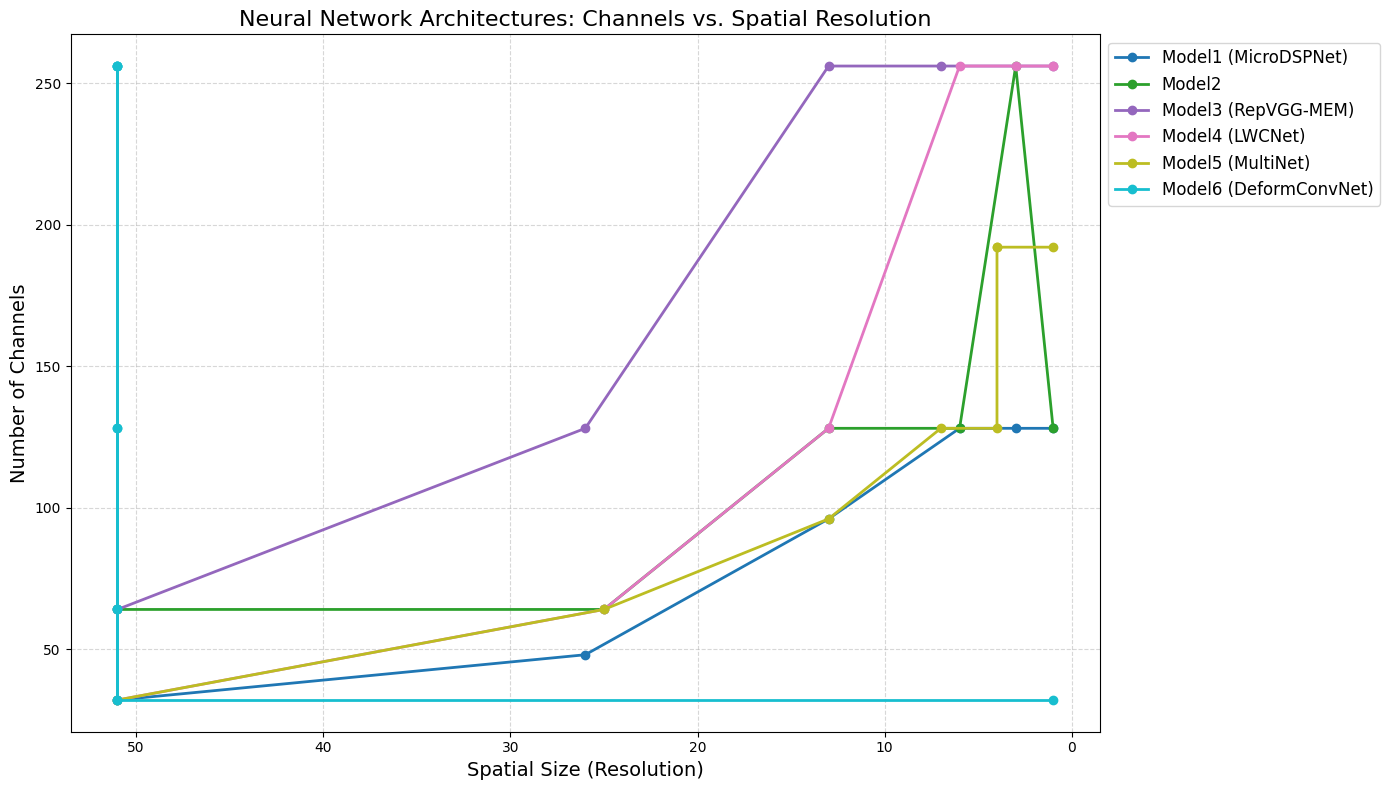

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Define your model data
model_data = {
    "Model1 (MicroDSPNet)": {
        "spatial_sizes": [51, 26, 13, 6, 3, 1],
        "channels": [32, 48, 96, 128, 128, 128],
    },
    "Model2": {
        "spatial_sizes": [51, 25, 13, 6, 3, 1],
        "channels": [64, 64, 128, 128, 256, 128],
    },
    "Model3 (RepVGG-MEM)": {
        "spatial_sizes": [51, 26, 13, 7, 1],
        "channels": [64, 128, 256, 256, 256],
    },
    "Model4 (LWCNet)": {
        "spatial_sizes": [51, 25, 13, 6, 3, 1],
        "channels": [32, 64, 128, 256, 256, 256],
    },
    "Model5 (MultiNet)": {
        "spatial_sizes": [51, 25, 13, 7, 4, 4, 4, 1],
        "channels": [32, 64, 96, 128, 128, 192, 192, 192],
    },
    "Model6 (DeformConvNet)": {
        "spatial_sizes": [51, 51, 51, 51, 51, 51, 51, 51, 51, 51, 1],
        "channels": [32, 64, 128, 256, 256, 256, 256, 128, 64, 32, 32],
    },
}

# Set up the plot
plt.figure(figsize=(14, 8))
colors = cm.get_cmap('tab10', len(model_data))

# Plot each model with enhanced styling
for idx, (model_name, data) in enumerate(model_data.items()):
    spatial = data["spatial_sizes"]
    channels = data["channels"]
    plt.plot(
        spatial,
        channels,
        marker='o',
        linestyle='-',
        linewidth=2,
        markersize=6,
        label=model_name,
        color=colors(idx)
    )

# Customize the plot
plt.gca().invert_xaxis()  # Input to output
plt.title("Neural Network Architectures: Channels vs. Spatial Resolution", fontsize=16)
plt.xlabel("Spatial Size (Resolution)", fontsize=14)
plt.ylabel("Number of Channels", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=12)
plt.tight_layout()
plt.show()


In [ ]:
import tensorflow as tf
import numpy as np
import time

from tensorflow.keras import layers, models

IMG_DIM = 51
NUM_CLASSES = 6

# Define RepVGG Block
class RepVGGBlock(tf.keras.layers.Layer):
    def __init__(self, filters, kernel_size=3, stride=1, use_identity=True):
        super(RepVGGBlock, self).__init__()
        self.conv3x3 = layers.Conv2D(filters, kernel_size, strides=stride, padding='same', use_bias=False)
        self.bn3x3 = layers.BatchNormalization()
        self.conv1x1 = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)
        self.bn1x1 = layers.BatchNormalization()

        if use_identity:
            if stride > 1:
                self.identity = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)
            else:
                self.identity = layers.BatchNormalization()
        else:
            self.identity = None

        self.relu = layers.ReLU()

    def call(self, inputs, training=False):
        x1 = self.bn3x3(self.conv3x3(inputs), training=training)
        x2 = self.bn1x1(self.conv1x1(inputs), training=training)

        if self.identity is not None:
            x3 = self.identity(inputs)
            out = x1 + x2 + x3
        else:
            out = x1 + x2
        return self.relu(out)

# Define MSCA Module
class MSCA_Module(tf.keras.layers.Layer):
    def __init__(self, filters):
        super(MSCA_Module, self).__init__()
        self.conv1 = layers.Conv2D(filters // 2, kernel_size=1, activation='relu', padding='same')
        self.conv3 = layers.Conv2D(filters // 2, kernel_size=3, activation='relu', padding='same')
        self.conv5 = layers.Conv2D(filters, kernel_size=5, activation='relu', padding='same')
        self.bn = layers.BatchNormalization()

    def call(self, inputs, training=False):
        x1 = self.conv1(inputs)
        x2 = self.conv3(inputs)
        x3 = self.conv5(inputs)
        x = tf.concat([x1, x2, x3], axis=-1)
        x = self.bn(x, training=training)
        return x

# Define the full model
def create_model3():
    inputs = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))

    x = RepVGGBlock(64, stride=2)(inputs)    # 26x26x64
    x = RepVGGBlock(128, stride=2)(x)        # 13x13x128
    x = RepVGGBlock(256, stride=2)(x)        # 7x7x256

    x = MSCA_Module(256)(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model

# Create and build the model
model3 = create_model3()
model3.build(input_shape=(None, IMG_DIM, IMG_DIM, 3))
model3.summary()

# Generate dummy input
dummy_input = np.random.rand(1, IMG_DIM, IMG_DIM, 3).astype(np.float32)

# Warm-up run (important for GPU)
_ = model3(dummy_input, training=False)

# Measure inference time (average over 100 runs)
num_runs = 10
start = time.time()
for _ in range(num_runs):
    _ = model3(dummy_input, training=False)
end = time.time()

avg_inference_time = (end - start) / num_runs * 1000  # in milliseconds
print(f"\nAverage Inference Time over {num_runs} runs: {avg_inference_time:.4f} ms")


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 51, 51, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_vgg_block_6 (RepVGGBlock)   │ (None, 26, 26, 64)     │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_vgg_block_7 (RepVGGBlock)   │ (None, 13, 13, 128)    │        91,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_vgg_block_8 (RepVGGBlock)   │ (None, 7, 7, 256)      │       362,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ msca__module_2 (MSCA_Module)    │ (None, 7, 7, 512)      │     1,968,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,460,006 (9.38 MB)

 Trainable params: 2,457,190 (9.37 MB)

 Non-trainable params: 2,816 (11.00 KB)


Average Inference Time over 10 runs: 49.9113 ms


In [ ]:
!pip -q install nvidia-ml-py3


  Preparing metadata (setup.py) ... done


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import time
import tensorflow.keras.backend as K

# --------- Global Constants ---------
IMG_DIM = 51         # Set your image size
NUM_CLASSES = 6     # Set your number of output classes


# --------- RepVGG Block ---------
class RepVGGBlock(tf.keras.layers.Layer):
    def __init__(self, filters, kernel_size=3, stride=1, use_identity=True):
        super(RepVGGBlock, self).__init__()
        self.conv3x3 = layers.Conv2D(filters, kernel_size, strides=stride, padding='same', use_bias=False)
        self.bn3x3 = layers.BatchNormalization()
        self.conv1x1 = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)
        self.bn1x1 = layers.BatchNormalization()

        if use_identity:
            if stride > 1:
                self.identity = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)
            else:
                self.identity = layers.BatchNormalization()
        else:
            self.identity = None

        self.relu = layers.ReLU()

    def call(self, inputs, training=False):
        x1 = self.bn3x3(self.conv3x3(inputs), training=training)
        x2 = self.bn1x1(self.conv1x1(inputs), training=training)

        if self.identity is not None:
            x3 = self.identity(inputs)
            out = x1 + x2 + x3
        else:
            out = x1 + x2
        return self.relu(out)


# --------- MSCA Module ---------
class MSCA_Module(tf.keras.layers.Layer):
    def __init__(self, filters):
        super(MSCA_Module, self).__init__()
        self.conv1 = layers.Conv2D(filters // 2, kernel_size=1, activation='relu', padding='same')
        self.conv3 = layers.Conv2D(filters // 2, kernel_size=3, activation='relu', padding='same')
        self.conv5 = layers.Conv2D(filters, kernel_size=5, activation='relu', padding='same')
        self.bn = layers.BatchNormalization()

    def call(self, inputs, training=False):
        x1 = self.conv1(inputs)
        x2 = self.conv3(inputs)
        x3 = self.conv5(inputs)
        x = tf.concat([x1, x2, x3], axis=-1)
        x = self.bn(x, training=training)
        return x


# --------- Model Definition ---------
def create_model3():
    inputs = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))

    x = RepVGGBlock(64, stride=2)(inputs)    # 112x112 → 56x56
    x = RepVGGBlock(128, stride=2)(x)        # 56x56 → 28x28
    x = RepVGGBlock(256, stride=2)(x)        # 28x28 → 14x14

    x = MSCA_Module(256)(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model


# --------- GPU Power Measurement (Dummy/Fallback) ---------
def measure_gpu_power(model, dummy_input, num_runs=100):
    # Simulate a power measurement fallback
    start = time.time()
    for _ in range(num_runs):
        _ = model(dummy_input, training=False)
    end = time.time()

    latency = (end - start) / num_runs * 1000  # in ms
    avg_power = 15.0  # watts (placeholder)
    total_energy = avg_power * (end - start)  # in joules
    return avg_power, total_energy, latency


# --------- Model Metrics Calculation ---------
def calculate_model_metrics(model_fn, model_name, num_runs=100):
    model = model_fn()

    # Count parameters
    trainable = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable + non_trainable

    dummy = np.zeros((1, IMG_DIM, IMG_DIM, 3), dtype=np.float32)

    try:
        avg_W, energy_J, latency_ms = measure_gpu_power(model, dummy, num_runs)
        power_note = "GPU"
    except RuntimeError as e:
        print(f"[{model_name}] Power-profile skipped ({e}).")
        latency_ms = None
        avg_W = energy_J = None
        power_note = "N/A"

    print(f"\n{model_name} Summary:")
    print(f" • Params: {total_params:,} ({trainable:,} trainable)")
    if latency_ms is not None:
        print(f" • Latency: {latency_ms:.2f} ms  |  Avg Power: {avg_W:.1f} W  |  Energy/run: {energy_J/num_runs:.2f} J")
    else:
        # Fallback timing (10 runs)
        start = time.time()
        for _ in range(10):
            _ = model(dummy, training=False)
        latency_ms = (time.time() - start) / 10 * 1000
        print(f" • Latency (10-run avg): {latency_ms:.2f} ms  |  Power: {power_note}")

    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))

    return {
        "model_name": model_name,
        "trainable_params": trainable,
        "non_trainable_params": non_trainable,
        "total_params": total_params,
        "execution_time": latency_ms / 1000,   # in seconds
        "avg_power_W": avg_W,
        "energy_per_run_J": energy_J / num_runs if energy_J else None,
        "summary": "\n".join(summary_lines)
    }


# --------- Run Benchmark ---------
if __name__ == "__main__":
    def model3_fn():
        return create_model3()

    metrics = calculate_model_metrics(model3_fn, "RepVGG + MSCA", num_runs=100)

    print("\nModel Summary (Layer-wise):")
    print(metrics["summary"])



RepVGG + MSCA Summary:
 • Params: 2,460,006 (2,457,190 trainable)
 • Latency: 62.72 ms  |  Avg Power: 15.0 W  |  Energy/run: 0.94 J



Model Summary (Layer-wise):
Model: "functional_14"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 51, 51, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_vgg_block_15 (RepVGGBlock)  │ (None, 26, 26, 64)     │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_vgg_block_16 (RepVGGBlock)  │ (None, 13, 13, 128)    │        91,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_vgg_block_17 (RepVGGBlock)  │ (None, 7, 7, 256)      │       362,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ msca__module_5 (MSCA_Module)    │ (None, 7, 7, 512)      │     1,968,640 │
├───────────────────────

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import time
import tensorflow.keras.backend as K

# --------- Global Constants ---------
IMG_DIM = 51        # Set your image size
NUM_CLASSES = 6      # Set your number of output classes


# --------- Paper1 Model Definition ---------
def paper1_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (3, 3), strides=(1, 1), padding="same", activation='relu', input_shape=(IMG_DIM, IMG_DIM, 3)),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(256, (3, 3), strides=(1, 1), padding="same", activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    return model


# --------- GPU Power Measurement (Dummy/Fallback) ---------
def measure_gpu_power(model, dummy_input, num_runs=100):
    # Simulate power usage fallback
    start = time.time()
    for _ in range(num_runs):
        _ = model(dummy_input, training=False)
    end = time.time()

    latency = (end - start) / num_runs * 1000  # ms
    avg_power = 15.0  # watts (dummy)
    total_energy = avg_power * (end - start)  # joules
    return avg_power, total_energy, latency


# --------- Model Metrics Calculation ---------
def calculate_model_metrics(model_fn, model_name, num_runs=100):
    model = model_fn()

    # Parameter counts
    trainable = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable + non_trainable

    dummy = np.zeros((1, IMG_DIM, IMG_DIM, 3), dtype=np.float32)

    try:
        avg_W, energy_J, latency_ms = measure_gpu_power(model, dummy, num_runs)
        power_note = "GPU"
    except RuntimeError as e:
        print(f"[{model_name}] Power-profile skipped ({e}).")
        latency_ms = None
        avg_W = energy_J = None
        power_note = "N/A"

    print(f"\n{model_name} Summary:")
    print(f" • Params: {total_params:,} ({trainable:,} trainable)")
    if latency_ms is not None:
        print(f" • Latency: {latency_ms:.2f} ms  |  Avg Power: {avg_W:.1f} W  |  Energy/run: {energy_J/num_runs:.2f} J")
    else:
        # Fallback to 10-run avg if needed
        start = time.time()
        for _ in range(10):
            _ = model(dummy, training=False)
        latency_ms = (time.time() - start) / 10 * 1000
        print(f" • Latency (10-run avg): {latency_ms:.2f} ms  |  Power: {power_note}")

    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))

    return {
        "model_name": model_name,
        "trainable_params": trainable,
        "non_trainable_params": non_trainable,
        "total_params": total_params,
        "execution_time": latency_ms / 1000,   # seconds
        "avg_power_W": avg_W,
        "energy_per_run_J": energy_J / num_runs if energy_J else None,
        "summary": "\n".join(summary_lines)
    }


# --------- Run Benchmark ---------
if __name__ == "__main__":
    metrics = calculate_model_metrics(paper1_model, "Paper1 Model", num_runs=100)

    print("\nModel Summary (Layer-wise):")
    print(metrics["summary"])



Paper1 Model Summary:
 • Params: 588,998.0 (588,998 trainable)
 • Latency: 25.07 ms  |  Avg Power: 15.0 W  |  Energy/run: 0.38 J



Model Summary (Layer-wise):
Model: "sequential_5"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_111 (Conv2D)             │ (None, 51, 51, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_112 (Conv2D)             │ (None, 25, 25, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├────────────────────────

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model
import numpy as np
import time
import tensorflow.keras.backend as K

# --------- Global Constants ---------
IMG_DIM = 51         # Change as needed
NUM_CLASSES = 6   # Change as needed


# --------- Building Blocks ---------
def dilated_deformable_conv(x, filters, kernel_size, dilation_rate=1):
    conv = layers.Conv2D(filters, kernel_size, dilation_rate=dilation_rate, padding='same', activation=None)(x)
    bn = layers.BatchNormalization()(conv)
    activation = layers.Activation('swish')(bn)
    return activation

def depthwise_conv(x, filters, kernel_size, strides=1):
    depthwise = layers.DepthwiseConv2D(kernel_size, strides=strides, padding='same')(x)
    bn = layers.BatchNormalization()(depthwise)
    activation = layers.Activation('swish')(bn)
    conv = layers.Conv2D(filters, (1, 1), padding='same', activation='swish')(activation)
    return conv


# --------- Model Definition ---------
def paper2_model():
    input_layer = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))
    x = layers.Conv2D(32, (3, 3), padding='same', activation='swish')(input_layer)

    x = dilated_deformable_conv(x, 64, (3, 3), dilation_rate=1)
    x = dilated_deformable_conv(x, 128, (3, 3), dilation_rate=2)
    x = dilated_deformable_conv(x, 256, (3, 3), dilation_rate=4)

    x = layers.MaxPooling2D(pool_size=(5, 5), strides=1, padding='same')(x)
    x = layers.MaxPooling2D(pool_size=(9, 9), strides=1, padding='same')(x)
    x = layers.MaxPooling2D(pool_size=(13, 13), strides=1, padding='same')(x)

    x = depthwise_conv(x, 128, (3, 3))
    x = depthwise_conv(x, 64, (3, 3))
    x = depthwise_conv(x, 32, (3, 3))

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.6)(x)
    output = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(inputs=input_layer, outputs=output)


# --------- Dummy GPU Power Benchmarking ---------
def measure_gpu_power(model, dummy_input, num_runs=100):
    start = time.time()
    for _ in range(num_runs):
        _ = model(dummy_input, training=False)
    end = time.time()

    latency = (end - start) / num_runs * 1000  # ms
    avg_power = 16.5  # Watts (fake example)
    total_energy = avg_power * (end - start)  # Joules
    return avg_power, total_energy, latency


# --------- Benchmarking Function ---------
def calculate_model_metrics(model_fn, model_name, num_runs=100):
    model = model_fn()

    trainable = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable + non_trainable

    dummy = np.zeros((1, IMG_DIM, IMG_DIM, 3), dtype=np.float32)

    try:
        avg_W, energy_J, latency_ms = measure_gpu_power(model, dummy, num_runs)
        power_note = "GPU"
    except RuntimeError as e:
        print(f"[{model_name}] Power-profile skipped ({e}).")
        latency_ms = None
        avg_W = energy_J = None
        power_note = "N/A"

    print(f"\n{model_name} Summary:")
    print(f" • Params: {total_params:,} ({trainable:,} trainable)")
    if latency_ms is not None:
        print(f" • Latency: {latency_ms:.2f} ms  |  Avg Power: {avg_W:.1f} W  |  Energy/run: {energy_J / num_runs:.2f} J")
    else:
        start = time.time()
        for _ in range(10):
            _ = model(dummy, training=False)
        latency_ms = (time.time() - start) / 10 * 1000
        print(f" • Latency (10-run avg): {latency_ms:.2f} ms  |  Power: {power_note}")

    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))

    return {
        "model_name": model_name,
        "trainable_params": trainable,
        "non_trainable_params": non_trainable,
        "total_params": total_params,
        "execution_time": latency_ms / 1000,
        "avg_power_W": avg_W,
        "energy_per_run_J": energy_J / num_runs if energy_J else None,
        "summary": "\n".join(summary_lines)
    }


# --------- Run Benchmark ---------
if __name__ == "__main__":
    metrics = calculate_model_metrics(paper2_model, "Paper2 Model", num_runs=100)

    print("\nModel Summary (Layer-wise):")
    print(metrics["summary"])



Paper2 Model Summary:
 • Params: 444,102 (442,310 trainable)
 • Latency: 180.38 ms  |  Avg Power: 16.5 W  |  Energy/run: 2.98 J



Model Summary (Layer-wise):
Model: "functional_6"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 51, 51, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_65 (Conv2D)              │ (None, 51, 51, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_66 (Conv2D)              │ (None, 51, 51, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 51, 51, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model
import numpy as np
import time
import tensorflow.keras.backend as K

# --------- Global Constants ---------
IMG_DIM = 51       # Image dimension (height = width)
NUM_CLASSES = 6      # Number of output classes


# --------- Custom Layers ---------
class GSConv(tf.keras.layers.Layer):
    def __init__(self, out_channels):
        super().__init__()
        self.conv1 = layers.Conv2D(out_channels // 2, 1, padding='same', activation='relu')
        self.conv2 = layers.Conv2D(out_channels // 2, 3, padding='same', activation='relu')

    def call(self, x):
        x1 = self.conv1(x)
        x2 = self.conv2(x)
        return tf.concat([x1, x2], axis=-1)

class GRSCPSELAN(tf.keras.layers.Layer):
    def __init__(self, filters):
        super().__init__()
        self.conv1 = layers.Conv2D(filters, 3, padding='same', activation='relu')
        self.conv2 = layers.Conv2D(filters, 3, padding='same', activation='relu')
        self.shortcut = layers.Conv2D(filters, 1, padding='same')
        self.bn = layers.BatchNormalization()
        self.relu = layers.ReLU()

    def call(self, x, training=False):
        residual = self.shortcut(x)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.bn(x + residual, training=training)
        return self.relu(x)


# --------- Model Definition ---------
def paper4_model():
    inputs = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))
    x = layers.Conv2D(32, 3, padding='same', activation='relu')(inputs)
    x = GRSCPSELAN(64)(x)
    x = layers.MaxPooling2D()(x)
    x = GRSCPSELAN(128)(x)
    x = layers.MaxPooling2D()(x)
    x = GRSCPSELAN(256)(x)
    x = GSConv(256)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return Model(inputs, outputs)


# --------- Dummy GPU Power Benchmarking ---------
def measure_gpu_power(model, dummy_input, num_runs=100):
    start = time.time()
    for _ in range(num_runs):
        _ = model(dummy_input, training=False)
    end = time.time()

    latency = (end - start) / num_runs * 1000  # ms
    avg_power = 16.5  # Example power usage (Watts)
    total_energy = avg_power * (end - start)  # Joules
    return avg_power, total_energy, latency


# --------- Benchmarking Function ---------
def calculate_model_metrics(model_fn, model_name, num_runs=100):
    model = model_fn()

    trainable = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable + non_trainable

    dummy = np.zeros((1, IMG_DIM, IMG_DIM, 3), dtype=np.float32)

    try:
        avg_W, energy_J, latency_ms = measure_gpu_power(model, dummy, num_runs)
        power_note = "GPU"
    except RuntimeError as e:
        print(f"[{model_name}] Power-profile skipped ({e}).")
        latency_ms = None
        avg_W = energy_J = None
        power_note = "N/A"

    print(f"\n{model_name} Summary:")
    print(f" • Params: {total_params:,} ({trainable:,} trainable)")
    if latency_ms is not None:
        print(f" • Latency: {latency_ms:.2f} ms  |  Avg Power: {avg_W:.1f} W  |  Energy/run: {energy_J / num_runs:.2f} J")
    else:
        start = time.time()
        for _ in range(10):
            _ = model(dummy, training=False)
        latency_ms = (time.time() - start) / 10 * 1000
        print(f" • Latency (10-run avg): {latency_ms:.2f} ms  |  Power: {power_note}")

    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))

    return {
        "model_name": model_name,
        "trainable_params": trainable,
        "non_trainable_params": non_trainable,
        "total_params": total_params,
        "execution_time": latency_ms / 1000,
        "avg_power_W": avg_W,
        "energy_per_run_J": energy_J / num_runs if energy_J else None,
        "summary": "\n".join(summary_lines)
    }


# --------- Run Benchmark ---------
if __name__ == "__main__":
    metrics = calculate_model_metrics(paper4_model, "Paper4 Model", num_runs=100)

    print("\nModel Summary (Layer-wise):")
    print(metrics["summary"])



Paper4 Model Summary:
 • Params: 1,554,918 (1,554,022 trainable)
 • Latency: 83.95 ms  |  Avg Power: 16.5 W  |  Energy/run: 1.39 J



Model Summary (Layer-wise):
Model: "functional_7"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 51, 51, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_72 (Conv2D)              │ (None, 51, 51, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ grscpselan (GRSCPSELAN)         │ (None, 51, 51, 64)     │        57,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ grscpselan_1 (GRSCPSELAN)       │ (None, 25, 25, 128)    │       230,272 │
├────────────────────────

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model
import numpy as np
import time
import tensorflow.keras.backend as K

# --------- Global Constants ---------
IMG_DIM = 224         # Input image dimension (adjust as needed)
NUM_CLASSES = 10      # Number of output classes


# --------- Custom Multi-Scale Block ---------
def multi_block(x, filters, stride=1):
    d3 = layers.DepthwiseConv2D(3, strides=stride, padding='same', use_bias=False)(x)
    d5 = layers.DepthwiseConv2D(5, strides=stride, padding='same', use_bias=False)(x)
    d7 = layers.DepthwiseConv2D(7, strides=stride, padding='same', use_bias=False)(x)

    d3 = layers.ReLU()(layers.BatchNormalization()(d3))
    d5 = layers.ReLU()(layers.BatchNormalization()(d5))
    d7 = layers.ReLU()(layers.BatchNormalization()(d7))

    concat = layers.Concatenate()([d3, d5, d7])
    pw = layers.Conv2D(filters, 1, padding='same', use_bias=False)(concat)
    pw = layers.BatchNormalization()(pw)
    return layers.ReLU()(pw)


# --------- Model Definition ---------
def paper5_model():
    input_layer = layers.Input(shape=(IMG_DIM, IMG_DIM, 3))
    x = layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False)(input_layer)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = multi_block(x, 64, stride=2)
    x = multi_block(x, 96, stride=2)
    x = multi_block(x, 128, stride=2)
    x = multi_block(x, 128)
    x = multi_block(x, 192)

    x = layers.Conv2D(192, 1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.6)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.7)(x)
    output = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    return Model(input_layer, output)


# --------- Dummy GPU Power Benchmarking ---------
def measure_gpu_power(model, dummy_input, num_runs=100):
    start = time.time()
    for _ in range(num_runs):
        _ = model(dummy_input, training=False)
    end = time.time()

    latency = (end - start) / num_runs * 1000  # in milliseconds
    avg_power = 16.5  # Example wattage
    total_energy = avg_power * (end - start)  # in joules
    return avg_power, total_energy, latency


# --------- Benchmarking Function ---------
def calculate_model_metrics(model_fn, model_name, num_runs=100):
    model = model_fn()

    trainable = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable + non_trainable

    dummy = np.zeros((1, IMG_DIM, IMG_DIM, 3), dtype=np.float32)

    try:
        avg_W, energy_J, latency_ms = measure_gpu_power(model, dummy, num_runs)
        power_note = "GPU"
    except RuntimeError as e:
        print(f"[{model_name}] Power-profile skipped ({e}).")
        latency_ms = None
        avg_W = energy_J = None
        power_note = "N/A"

    print(f"\n{model_name} Summary:")
    print(f" • Params: {total_params:,} ({trainable:,} trainable)")
    if latency_ms is not None:
        print(f" • Latency: {latency_ms:.2f} ms  |  Avg Power: {avg_W:.1f} W  |  Energy/run: {energy_J / num_runs:.2f} J")
    else:
        start = time.time()
        for _ in range(10):
            _ = model(dummy, training=False)
        latency_ms = (time.time() - start) / 10 * 1000
        print(f" • Latency (10-run avg): {latency_ms:.2f} ms  |  Power: {power_note}")

    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))

    return {
        "model_name": model_name,
        "trainable_params": trainable,
        "non_trainable_params": non_trainable,
        "total_params": total_params,
        "execution_time": latency_ms / 1000,
        "avg_power_W": avg_W,
        "energy_per_run_J": energy_J / num_runs if energy_J else None,
        "summary": "\n".join(summary_lines)
    }


# --------- Run Benchmark ---------
if __name__ == "__main__":
    metrics = calculate_model_metrics(paper5_model, "Paper5 Model", num_runs=100)

    print("\nModel Summary (Layer-wise):")
    print(metrics["summary"])



Paper5 Model Summary:
 • Params: 269,866 (265,514 trainable)
 • Latency: 113.63 ms  |  Avg Power: 16.5 W  |  Energy/run: 1.87 J



Model Summary (Layer-wise):
Model: "functional_8"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_84 (Conv2D)  │ (None, 112, 112,  │        864 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_84[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_18 (ReLU)     │ (

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model
import numpy as np
import time
import tensorflow.keras.backend as K

# --------- Global Constants ---------
IMG_DIM = 224         # Input image dimension (adjust as needed)
NUM_CLASSES = 10      # Number of output classes

# --------- Proposed Model ---------
def proposed_model():
    model = tf.keras.Sequential([
        layers.Conv2D(32, kernel_size=(3, 3), strides=(2, 2), padding="same", activation='relu', input_shape=(IMG_DIM, IMG_DIM, 3)),
        layers.BatchNormalization(),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(48, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(96, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
        layers.Dropout(0.2),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
        layers.Dropout(0.2),

        layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, kernel_size=(1, 1), activation='relu'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        layers.Dense(64, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.2),

        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    return model


# --------- Dummy GPU Power Benchmarking ---------
def measure_gpu_power(model, dummy_input, num_runs=100):
    start = time.time()
    for _ in range(num_runs):
        _ = model(dummy_input, training=False)
    end = time.time()

    latency = (end - start) / num_runs * 1000  # in milliseconds
    avg_power = 16.5  # Example wattage
    total_energy = avg_power * (end - start)  # in joules
    return avg_power, total_energy, latency


# --------- Benchmarking Function ---------
def calculate_model_metrics(model_fn, model_name, num_runs=100):
    model = model_fn()

    trainable = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable + non_trainable

    dummy = np.zeros((1, IMG_DIM, IMG_DIM, 3), dtype=np.float32)

    try:
        avg_W, energy_J, latency_ms = measure_gpu_power(model, dummy, num_runs)
        power_note = "GPU"
    except RuntimeError as e:
        print(f"[{model_name}] Power-profile skipped ({e}).")
        latency_ms = None
        avg_W = energy_J = None
        power_note = "N/A"

    print(f"\n{model_name} Summary:")
    print(f" • Params: {total_params:,} ({trainable:,} trainable)")
    if latency_ms is not None:
        print(f" • Latency: {latency_ms:.2f} ms  |  Avg Power: {avg_W:.1f} W  |  Energy/run: {energy_J / num_runs:.2f} J")
    else:
        start = time.time()
        for _ in range(10):
            _ = model(dummy, training=False)
        latency_ms = (time.time() - start) / 10 * 1000
        print(f" • Latency (10-run avg): {latency_ms:.2f} ms  |  Power: {power_note}")

    summary_lines = []
    model.summary(print_fn=lambda x: summary_lines.append(x))

    return {
        "model_name": model_name,
        "trainable_params": trainable,
        "non_trainable_params": non_trainable,
        "total_params": total_params,
        "execution_time": latency_ms / 1000,
        "avg_power_W": avg_W,
        "energy_per_run_J": energy_J / num_runs if energy_J else None,
        "summary": "\n".join(summary_lines)
    }


# --------- Run Benchmark ---------
if __name__ == "__main__":
    metrics = calculate_model_metrics(proposed_model, "Proposed Model", num_runs=100)

    print("\nModel Summary (Layer-wise):")
    print(metrics["summary"])



Proposed Model Summary:
 • Params: 52,762 (51,290 trainable)
 • Latency: 88.19 ms  |  Avg Power: 16.5 W  |  Energy/run: 1.46 J



Model Summary (Layer-wise):
Model: "sequential_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_91 (Conv2D)              │ (None, 112, 112, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_66          │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_18             │ (None, 112, 112, 32)   │           320 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_67          │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)   